# FleetMind — Exploratory Data Analysis

## AI4I 2020 Predictive Maintenance Dataset

### Objectives

1. Understand dataset structure and data quality.
2. Investigate machine failure class imbalance.
3. Analyze operational feature distributions.
4. Examine relationships between machine conditions and failures.
5. Identify label inconsistencies and potential data leakage.
6. Establish a defensible preprocessing and evaluation strategy.

**Dataset:** UCI AI4I 2020 Predictive Maintenance  
**Observations:** 10,000  
**Target:** Machine failure (binary)

### Important limitations

The dataset is synthetic and contains failure-state labels rather
than verified future failure horizons. FleetMind's initial model
will classify observed failure conditions, not predict remaining
useful life.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Locate project root from the notebook directory.
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

df = pd.read_csv(DATA_PATH)

TARGET = "Machine failure"

FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

FEATURES = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

print(f"Dataset shape: {df.shape}")
print(f"Failure rate: {df[TARGET].mean():.2%}")

display(df.head())

Dataset shape: (10000, 14)
Failure rate: 3.39%


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


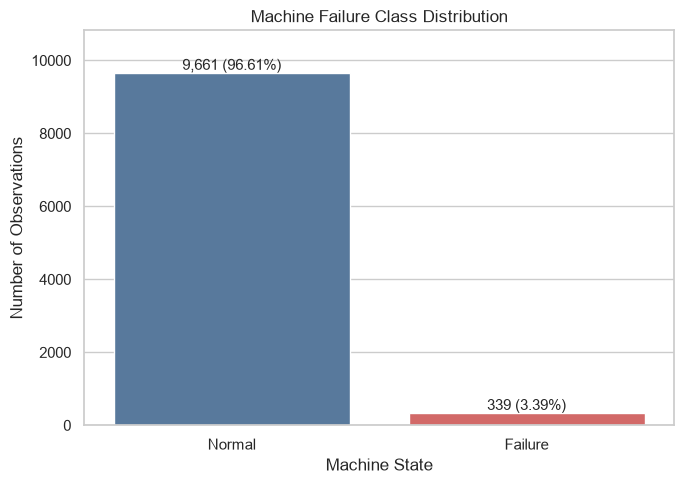

In [2]:
fig, ax = plt.subplots(figsize=(7, 5))

counts = df[TARGET].value_counts().sort_index()

sns.barplot(
    x=["Normal", "Failure"],
    y=counts.values,
    hue=["Normal", "Failure"],
    palette=["#4C78A8", "#E45756"],
    legend=False,
    ax=ax,
)

for i, count in enumerate(counts.values):
    ax.text(
        i,
        count + 80,
        f"{count:,} ({count / len(df):.2%})",
        ha="center",
        fontsize=11,
    )

ax.set_title("Machine Failure Class Distribution")
ax.set_xlabel("Machine State")
ax.set_ylabel("Number of Observations")
ax.set_ylim(0, counts.max() * 1.12)

plt.tight_layout()
plt.show()

## 2. Numerical Feature Distributions

This section examines the distributions of operational measurements,
including their central tendencies, variability, and potential outliers.

We first examine the complete dataset, then compare measurements
between normal and failed machine states.

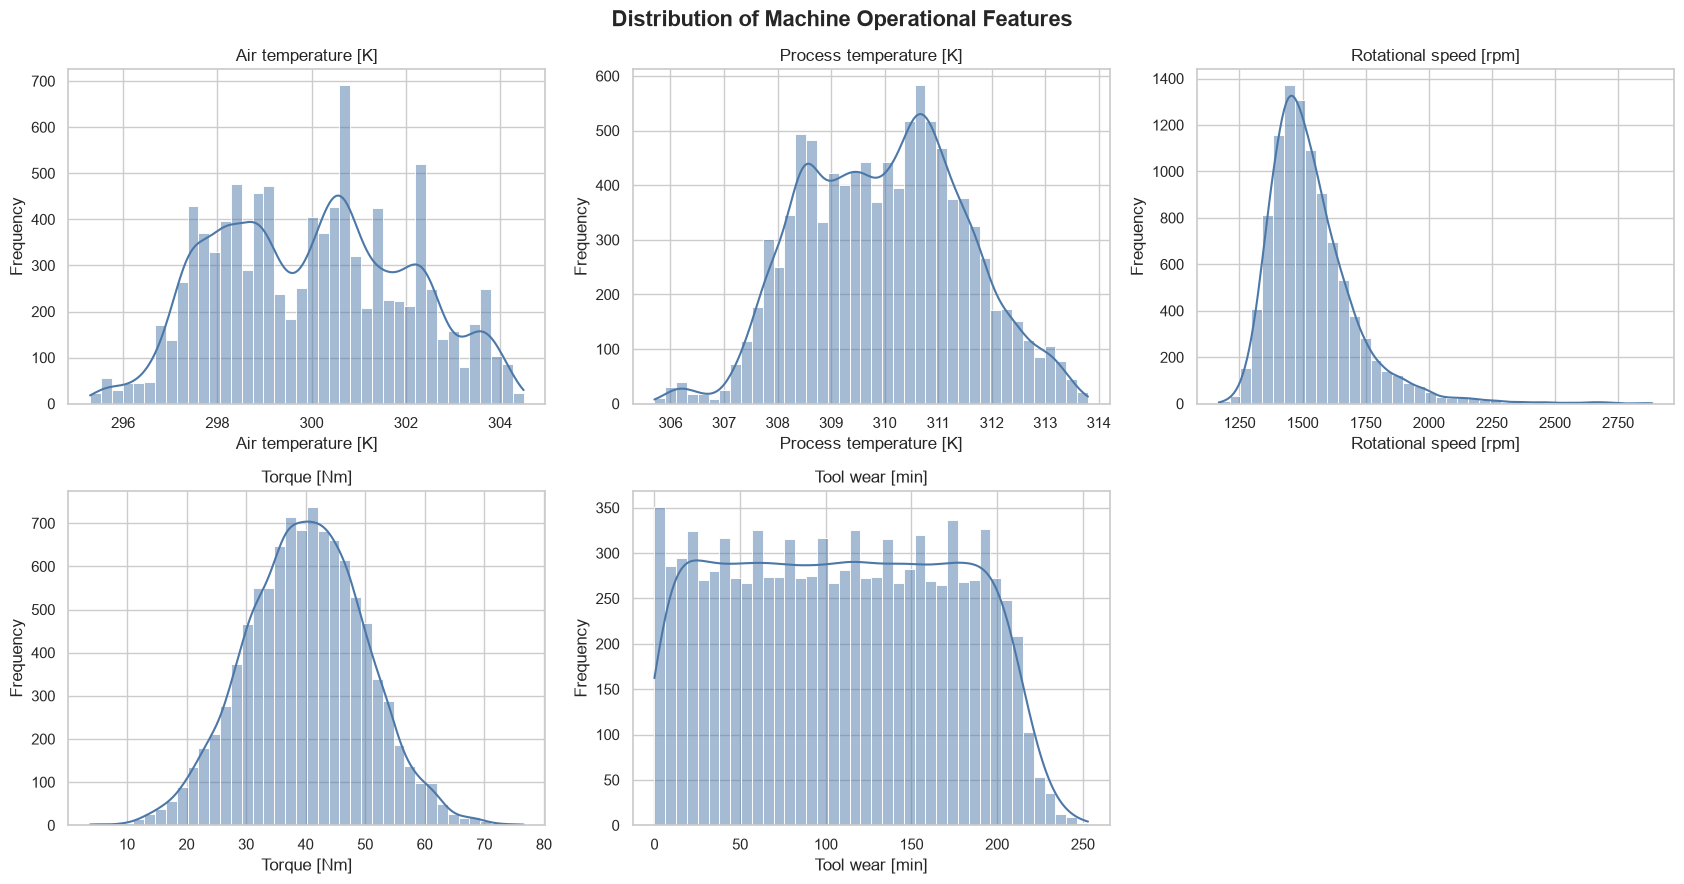

In [3]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=40,
        kde=True,
        ax=axes[i],
        color="#4C78A8",
    )

    axes[i].set_title(feature)
    axes[i].set_ylabel("Frequency")

for ax in axes[len(numeric_features):]:
    ax.axis("off")

fig.suptitle(
    "Distribution of Machine Operational Features",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

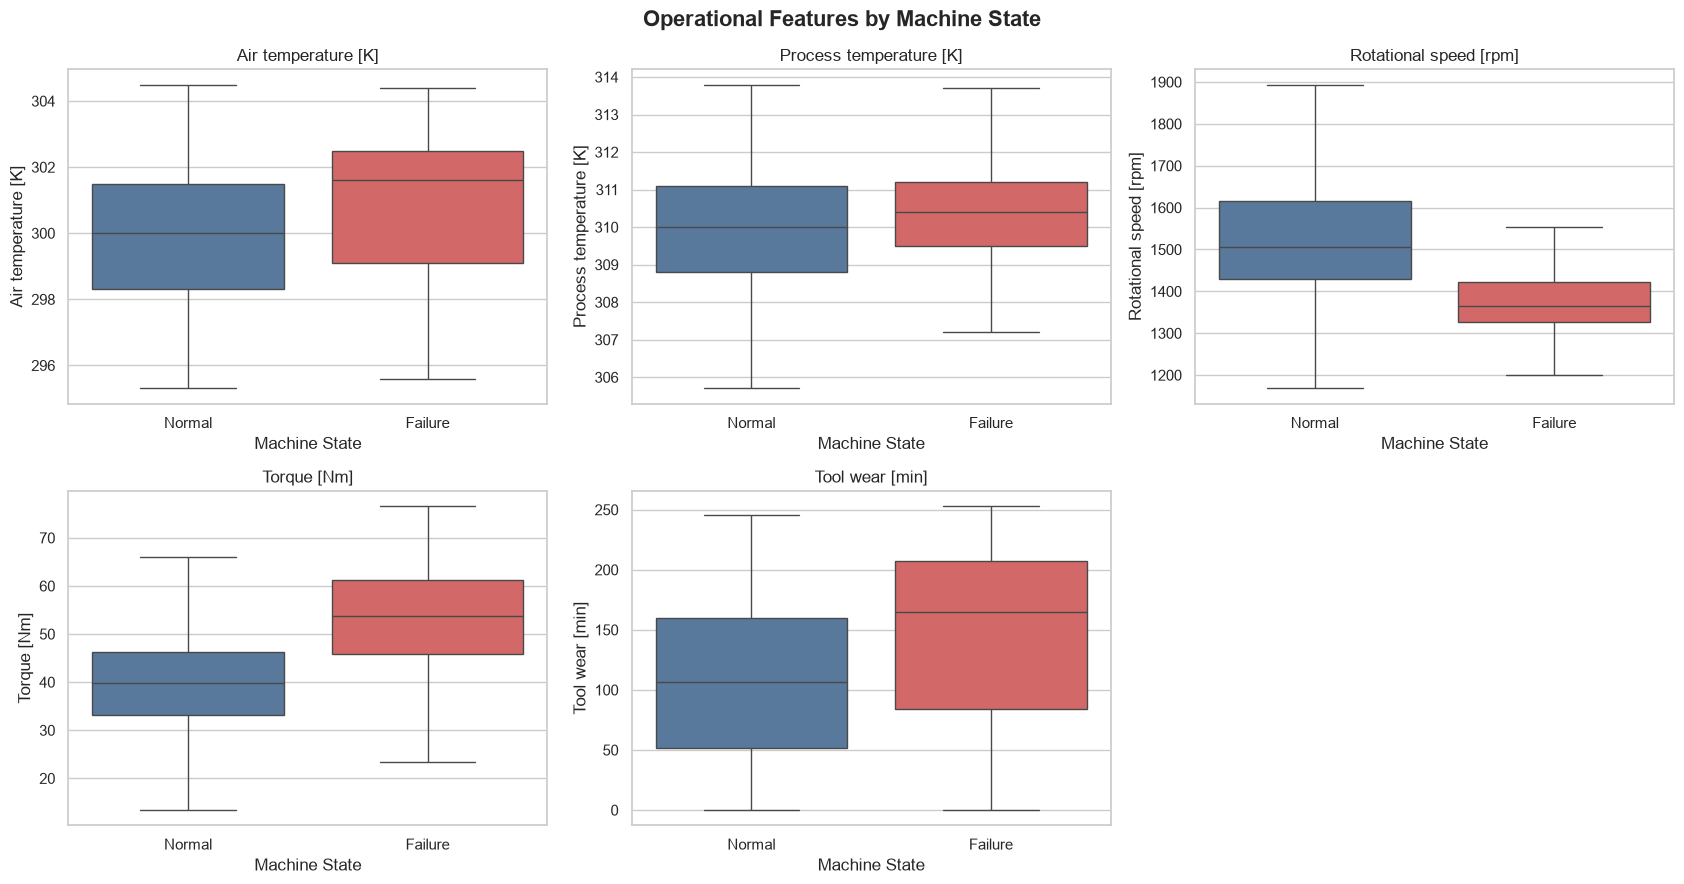

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        hue="Machine failure",
        palette=["#4C78A8", "#E45756"],
        legend=False,
        showfliers=False,
        ax=axes[i],
    )

    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Normal", "Failure"])
    axes[i].set_title(feature)
    axes[i].set_xlabel("Machine State")

for ax in axes[len(numeric_features):]:
    ax.axis("off")

fig.suptitle(
    "Operational Features by Machine State",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

In [5]:
group_stats = (
    df.groupby("Machine failure")[numeric_features]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(group_stats)

Air temperature [K]              Process temperature [K]  \
                               mean median   std                    mean   
Machine failure                                                            
0                            299.97  300.0  1.99                  310.00   
1                            300.89  301.6  2.07                  310.29   

                             Rotational speed [rpm]                  \
                median   std                   mean  median     std   
Machine failure                                                       
0                310.0  1.49                1540.26  1507.0  167.39   
1                310.4  1.36                1496.49  1365.0  384.94   

                Torque [Nm]               Tool wear [min]                
                       mean median    std            mean median    std  
Machine failure                                                          
0                     39.63   39.9   9.47          106.69  107.0  62.95  
1                     50.17   53.7  16.37          143.78  165.0  72.76

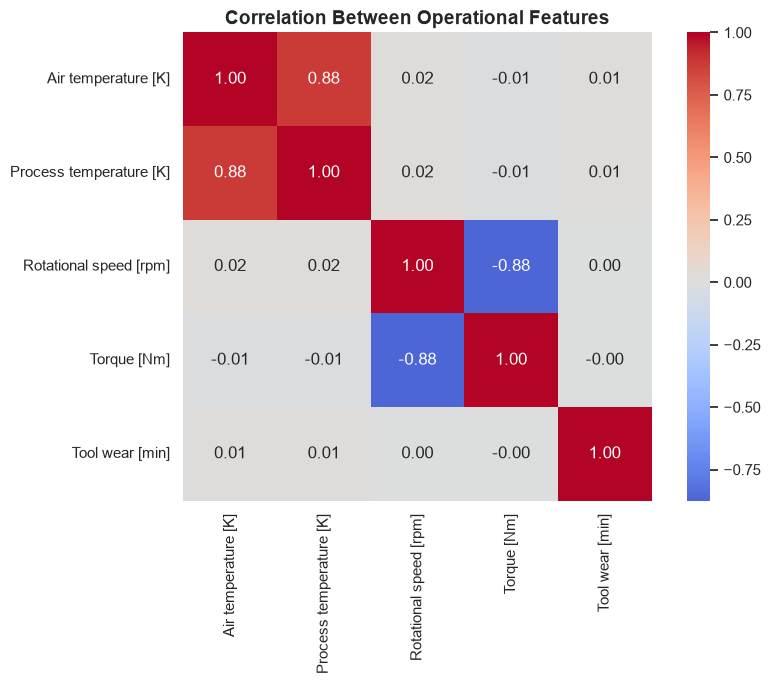

In [6]:
correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
)

plt.title(
    "Correlation Between Operational Features",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

In [7]:
import numpy as np

corr = df[numeric_features].corr()

# Keep each feature pair only once.
upper_triangle = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pairs = (
    upper_triangle.stack()
    .reset_index()
)

pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

pairs["Absolute correlation"] = (
    pairs["Correlation"].abs()
)

pairs = pairs.sort_values(
    "Absolute correlation",
    ascending=False,
)

display(pairs.head(10))

,Feature 1,Feature 2,Correlation,Absolute correlation
0,Air temperature [K],Process temperature [K],0.876107,0.876107
7,Rotational speed [rpm],Torque [Nm],-0.875027,0.875027
1,Air temperature [K],Rotational speed [rpm],0.022670,0.022670
4,Process temperature [K],Rotational speed [rpm],0.019277,0.019277
5,Process temperature [K],Torque [Nm],-0.014061,0.014061
3,Air temperature [K],Tool wear [min],0.013853,0.013853
2,Air temperature [K],Torque [Nm],-0.013778,0.013778
6,Process temperature [K],Tool wear [min],0.013488,0.013488
9,Torque [Nm],Tool wear [min],-0.003093,0.003093
8,Rotational speed [rpm],Tool wear [min],0.000223,0.000223


## 3. Operational Relationships and Failure Patterns

This section investigates relationships between machine measurements
and failure states, with particular attention to rotational speed,
torque, temperature, and accumulated tool wear.

The objective is to identify potentially nonlinear relationships
that may not be visible through Pearson correlation alone.

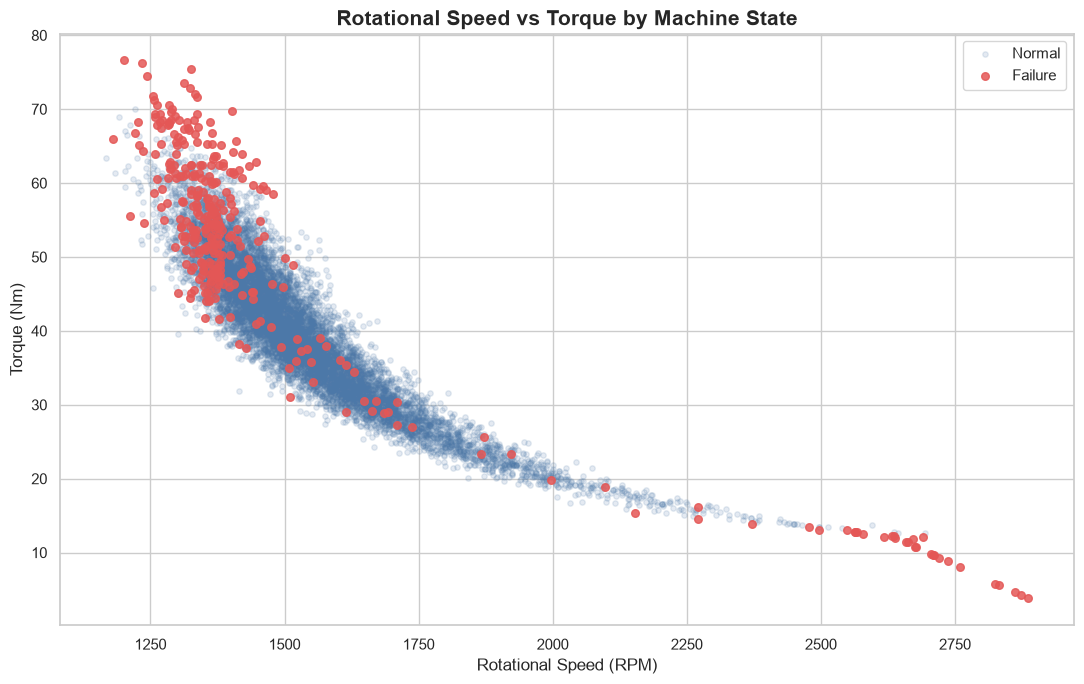

In [8]:
fig, ax = plt.subplots(figsize=(11, 7))

# Plot normal observations first.
normal = df[df["Machine failure"] == 0]
failed = df[df["Machine failure"] == 1]

ax.scatter(
    normal["Rotational speed [rpm]"],
    normal["Torque [Nm]"],
    alpha=0.15,
    s=15,
    color="#4C78A8",
    label="Normal",
)

# Overlay failures so they remain visible.
ax.scatter(
    failed["Rotational speed [rpm]"],
    failed["Torque [Nm]"],
    alpha=0.85,
    s=30,
    color="#E45756",
    label="Failure",
)

ax.set_title(
    "Rotational Speed vs Torque by Machine State",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel("Rotational Speed (RPM)")
ax.set_ylabel("Torque (Nm)")
ax.legend()

plt.tight_layout()
plt.show()

## 3.2 Analyze failure rates across tool-wear levels

Lets examine whether failure frequency increases as tool wear accumulates.

,Observations,Failures,Failure rate,Failure rate (%)
Wear group,,,,
0–49,2349,52,0.022137,2.213708
50–99,2271,51,0.022457,2.245707
100–149,2290,52,0.022707,2.270742
150–199,2289,61,0.026649,2.664919
200–253,801,123,0.153558,15.355805


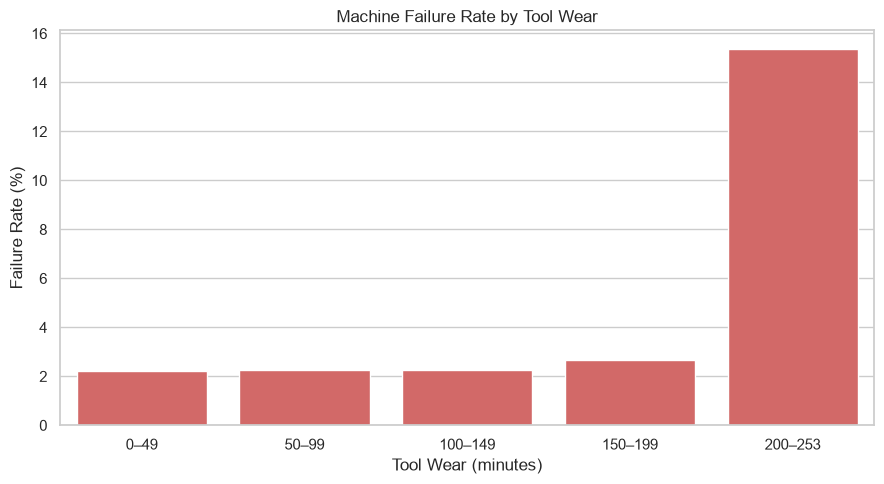

In [9]:
wear_bins = [0, 50, 100, 150, 200, 254]

wear_labels = [
    "0–49",
    "50–99",
    "100–149",
    "150–199",
    "200–253",
]

wear_analysis = df.copy()

wear_analysis["Wear group"] = pd.cut(
    wear_analysis["Tool wear [min]"],
    bins=wear_bins,
    labels=wear_labels,
    right=False,
)

wear_summary = (
    wear_analysis.groupby(
        "Wear group",
        observed=True,
    )["Machine failure"]
    .agg(["count", "sum", "mean"])
    .rename(
        columns={
            "count": "Observations",
            "sum": "Failures",
            "mean": "Failure rate",
        }
    )
)

wear_summary["Failure rate (%)"] = (
    wear_summary["Failure rate"] * 100
)

display(wear_summary)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=wear_summary.reset_index(),
    x="Wear group",
    y="Failure rate (%)",
    color="#E45756",
    ax=ax,
)

ax.set_title("Machine Failure Rate by Tool Wear")
ax.set_xlabel("Tool Wear (minutes)")
ax.set_ylabel("Failure Rate (%)")

plt.tight_layout()
plt.show()

## 4. Physically Derived Operational Features

We investigate temperature difference and mechanical power as
potentially informative representations of machine operating
conditions.

These variables are derived from existing sensor measurements
and do not require failure labels.

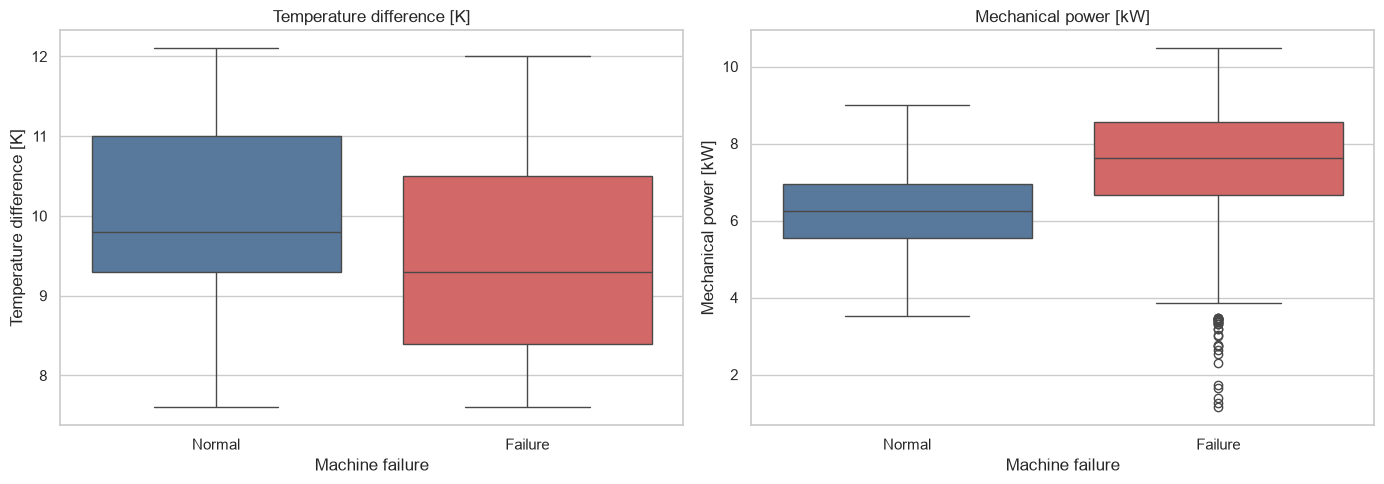


=== DERIVED FEATURE STATISTICS ===
                Temperature difference [K]                \
                                      mean median    std   
Machine failure                                            
0                                   10.022    9.8  0.988   
1                                    9.404    9.3  1.164   

                Mechanical power [kW]                
                                 mean median    std  
Machine failure                                      
0                               6.245  6.243  1.011  
1                               7.283  7.611  1.851  


In [10]:
import numpy as np

analysis_df = df.copy()

analysis_df["Temperature difference [K]"] = (
    analysis_df["Process temperature [K]"]
    - analysis_df["Air temperature [K]"]
)

analysis_df["Mechanical power [kW]"] = (
    2 * np.pi
    * analysis_df["Rotational speed [rpm]"]
    * analysis_df["Torque [Nm]"]
    / 60000
)

derived_features = [
    "Temperature difference [K]",
    "Mechanical power [kW]",
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for feature, ax in zip(derived_features, axes):
    sns.boxplot(
        data=analysis_df,
        x="Machine failure",
        y=feature,
        hue="Machine failure",
        palette=["#4C78A8", "#E45756"],
        legend=False,
        ax=ax,
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Normal", "Failure"])
    ax.set_title(feature)

plt.tight_layout()
plt.show()

print("\n=== DERIVED FEATURE STATISTICS ===")

print(
    analysis_df.groupby("Machine failure")[
        derived_features
    ].agg(["mean", "median", "std"]).round(3)
)

,Observations,Failures,Failure rate,Failure rate (%)
Power group,,,,
"(1.147, 4.915]",1000,40,0.040,4.0
"(4.915, 5.383]",1000,6,0.006,0.6
"(5.383, 5.718]",1000,5,0.005,0.5
"(5.718, 6.008]",1000,8,0.008,0.8
"(6.008, 6.271]",1000,12,0.012,1.2
"(6.271, 6.547]",1000,9,0.009,0.9
"(6.547, 6.833]",1000,24,0.024,2.4
"(6.833, 7.176]",1000,26,0.026,2.6
"(7.176, 7.641]",1000,40,0.040,4.0


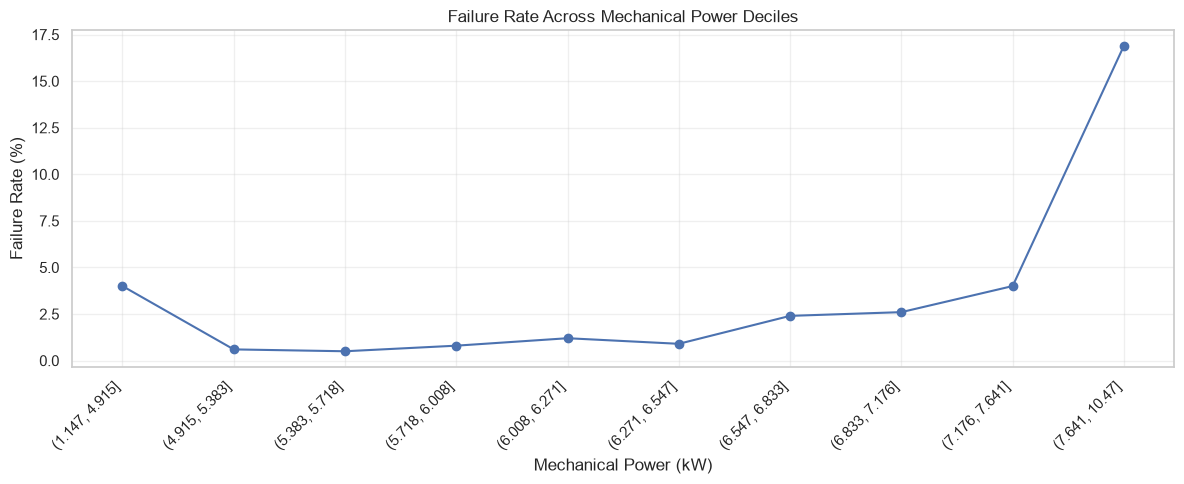

In [11]:
power_df = analysis_df.copy()

power_df["Power group"] = pd.qcut(
    power_df["Mechanical power [kW]"],
    q=10,
    duplicates="drop",
)

power_summary = (
    power_df.groupby("Power group", observed=True)[
        "Machine failure"
    ]
    .agg(["count", "sum", "mean"])
)

power_summary.columns = [
    "Observations",
    "Failures",
    "Failure rate",
]

power_summary["Failure rate (%)"] = (
    power_summary["Failure rate"] * 100
)

display(power_summary)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    range(len(power_summary)),
    power_summary["Failure rate (%)"],
    marker="o",
)

ax.set_xticks(range(len(power_summary)))
ax.set_xticklabels(
    [str(x) for x in power_summary.index],
    rotation=45,
    ha="right",
)

ax.set_title("Failure Rate Across Mechanical Power Deciles")
ax.set_xlabel("Mechanical Power (kW)")
ax.set_ylabel("Failure Rate (%)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Dataset Ordering and Leakage Assessment

This section examines whether observations exhibit patterns
associated with dataset ordering.

UDI is treated as a record identifier, not as an operational
feature or a verified timestamp.

The purpose is to identify potential distribution shifts and
limitations of random train/test splitting.

,Observations,Failures,Failure rate,Failure rate (%)
Sequence group,,,,
1,1000,23,0.023,2.3
2,1000,29,0.029,2.9
3,1000,22,0.022,2.2
4,1000,27,0.027,2.7
5,1000,134,0.134,13.4
6,1000,20,0.020,2.0
7,1000,23,0.023,2.3
8,1000,22,0.022,2.2
9,1000,17,0.017,1.7


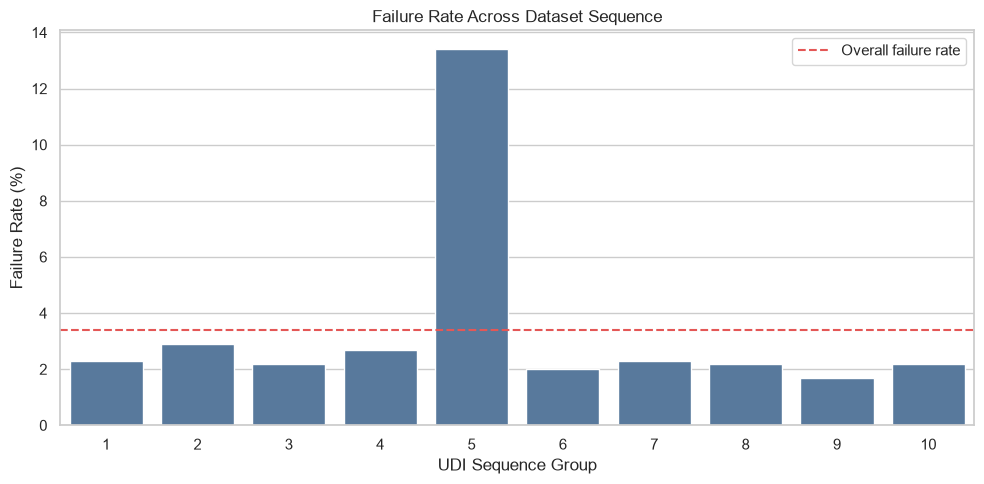

In [12]:
order_df = df.sort_values("UDI").copy()

order_df["Sequence group"] = pd.qcut(
    order_df["UDI"],
    q=10,
    labels=False,
) + 1

sequence_summary = (
    order_df.groupby("Sequence group")["Machine failure"]
    .agg(["count", "sum", "mean"])
    .rename(
        columns={
            "count": "Observations",
            "sum": "Failures",
            "mean": "Failure rate",
        }
    )
)

sequence_summary["Failure rate (%)"] = (
    sequence_summary["Failure rate"] * 100
)

display(sequence_summary)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=sequence_summary.reset_index(),
    x="Sequence group",
    y="Failure rate (%)",
    color="#4C78A8",
    ax=ax,
)

ax.axhline(
    df["Machine failure"].mean() * 100,
    color="#E45756",
    linestyle="--",
    label="Overall failure rate",
)

ax.set_title("Failure Rate Across Dataset Sequence")
ax.set_xlabel("UDI Sequence Group")
ax.set_ylabel("Failure Rate (%)")
ax.legend()

plt.tight_layout()
plt.show()

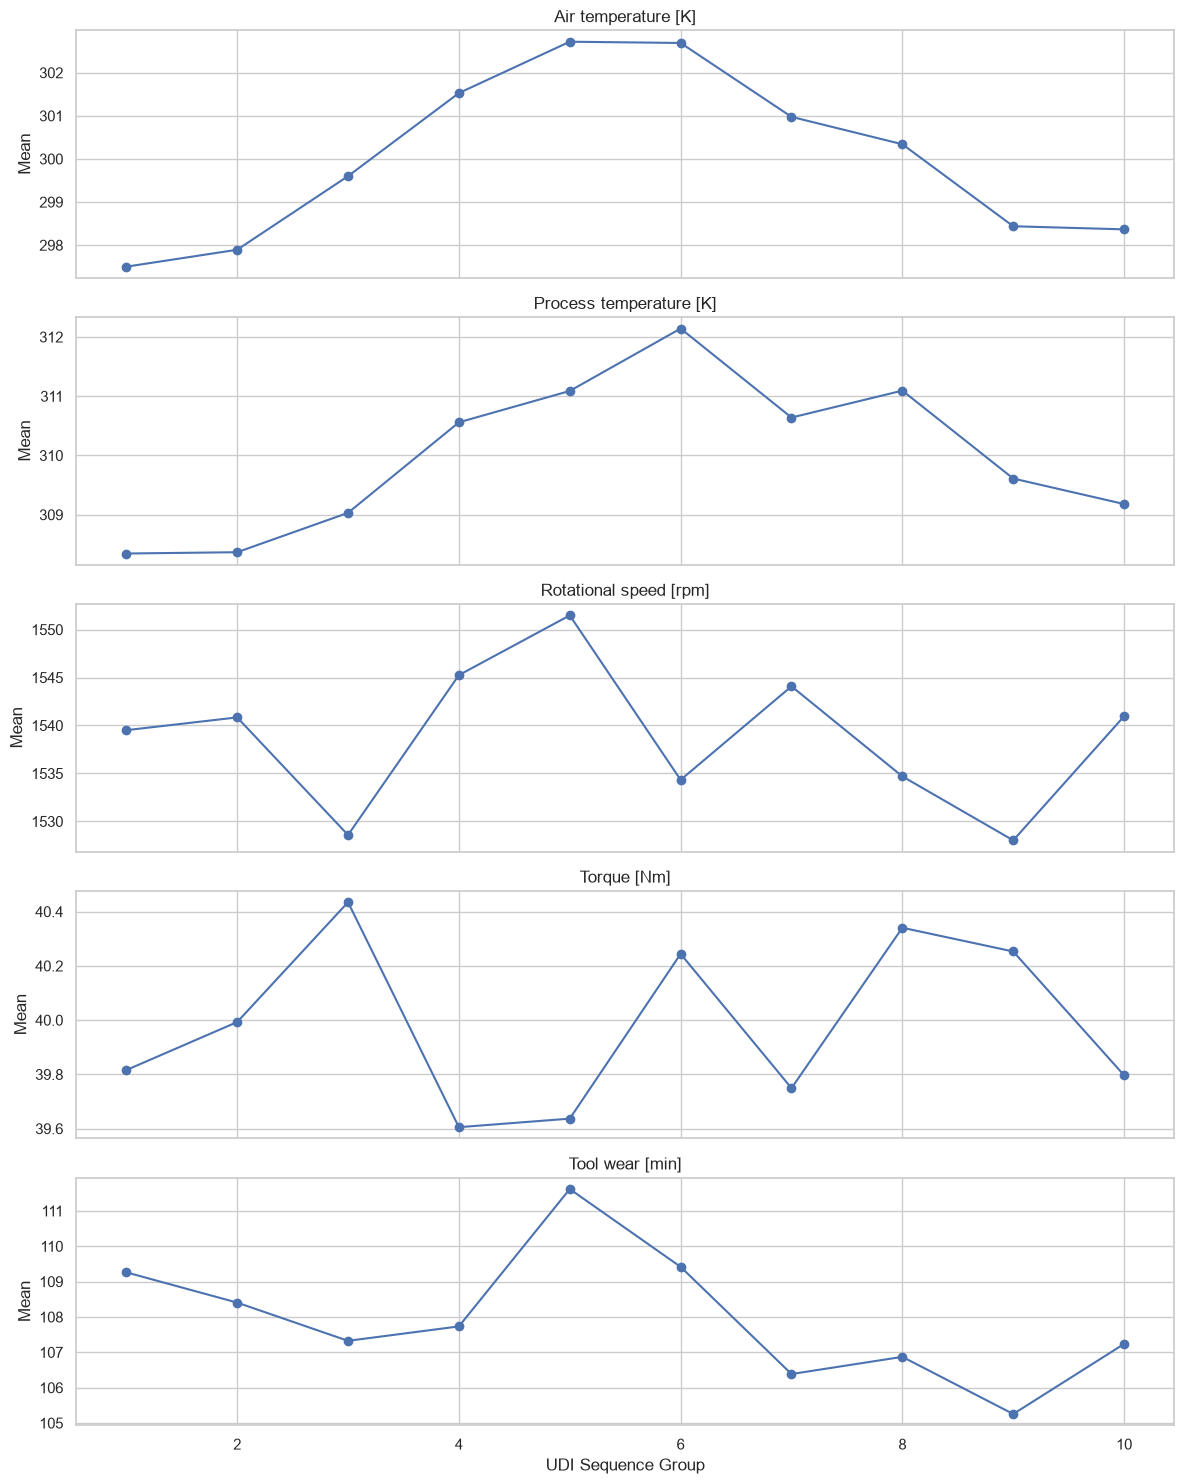

In [13]:
sequence_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

sequence_means = (
    order_df.groupby("Sequence group")[
        sequence_features
    ].mean()
)

fig, axes = plt.subplots(
    len(sequence_features),
    1,
    figsize=(12, 15),
    sharex=True,
)

for feature, ax in zip(sequence_features, axes):
    ax.plot(
        sequence_means.index,
        sequence_means[feature],
        marker="o",
    )

    ax.set_title(feature)
    ax.set_ylabel("Mean")

axes[-1].set_xlabel("UDI Sequence Group")

plt.tight_layout()
plt.show()

## What we're looking for
If temperature or failure rates change substantially across the ordered observations, a random split may mix observations from similar operating regimes into both training and test sets.

That can make the evaluation easier than deployment on genuinely new operating conditions.

A sequence-based split would provide a useful additional stress test, although it still would not prove real-world temporal generalization because UDI is not a verified timestamp.

Checking for potential target leakage
We have already identified five columns that must not enter the binary classifier:

TWF, HDF, PWF, OSF, and RNF.

These represent failure outcomes and would leak information about the target.

We should also exclude UDI and Product ID initially.

Our candidate model inputs are therefore:
MODEL_FEATURES = [    "Type",    "Air temperature [K]",    "Process temperature [K]",    "Rotational speed [rpm]",    "Torque [Nm]",    "Tool wear [min]",]



Two additional derived features may be evaluated:
DERIVED_FEATURES = [
    "Temperature difference [K]",
    "Mechanical power [kW]",
]

These derived features use only operational measurements, so they do not inherently leak target labels. They should be calculated consistently in the training and inference pipeline.

## 6. Investigation of Sequence-Dependent Failure Concentration

Sequence group 5 exhibits an unusually high failure rate.

This section investigates whether the concentration is associated
with temperature conditions, specific failure modes, or other
operational characteristics.

UDI is an ordering identifier, not a verified timestamp.

,TWF,HDF,PWF,OSF,RNF
Sequence group,,,,,
1,1,0,13,10,0
2,5,0,13,12,3
3,5,0,8,8,2
4,4,7,9,9,3
5,6,108,15,12,0
6,5,0,8,9,6
7,5,0,10,8,3
8,5,0,9,9,2
9,6,0,5,7,0


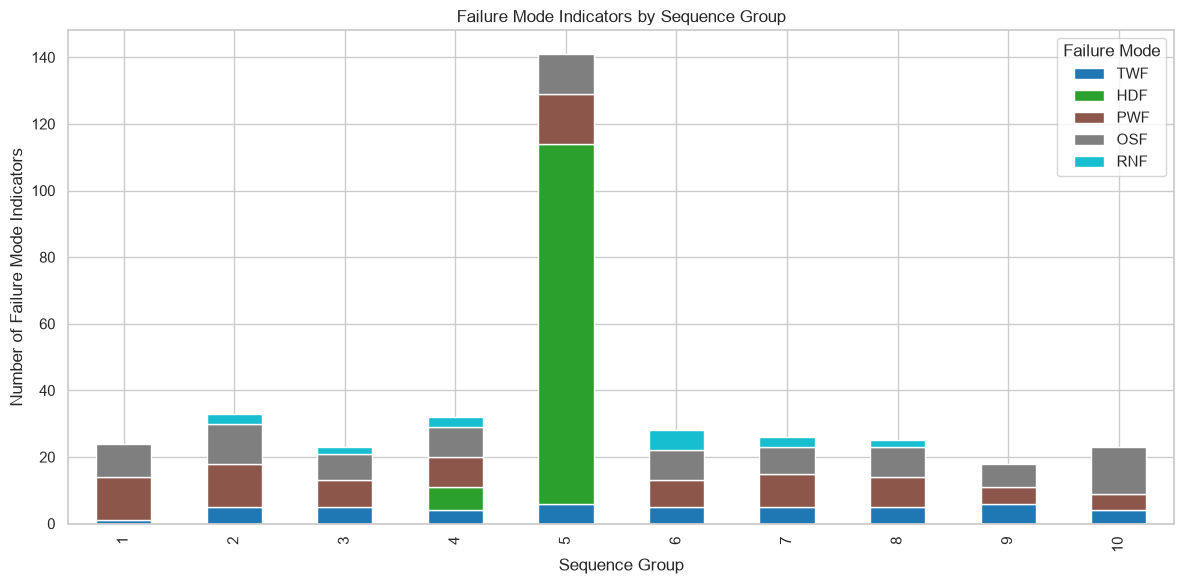

In [14]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

mode_summary = (
    order_df.groupby("Sequence group")[failure_modes]
    .sum()
)

display(mode_summary)

fig, ax = plt.subplots(figsize=(12, 6))

mode_summary.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    colormap="tab10",
)

ax.set_title("Failure Mode Indicators by Sequence Group")
ax.set_xlabel("Sequence Group")
ax.set_ylabel("Number of Failure Mode Indicators")
ax.legend(title="Failure Mode")

plt.tight_layout()
plt.show()

In [15]:
comparison_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

group_5 = order_df[order_df["Sequence group"] == 5]
other_groups = order_df[order_df["Sequence group"] != 5]

comparison = pd.DataFrame({
    "Group 5 mean": group_5[comparison_features].mean(),
    "Other groups mean": other_groups[comparison_features].mean(),
})

comparison["Difference"] = (
    comparison["Group 5 mean"]
    - comparison["Other groups mean"]
)

display(comparison.round(3))

,Group 5 mean,Other groups mean,Difference
Air temperature [K],302.718,299.703,3.015
Process temperature [K],311.088,309.885,1.203
Rotational speed [rpm],1551.482,1537.364,14.118
Torque [Nm],39.637,40.026,-0.389
Tool wear [min],111.617,107.544,4.073


In [16]:
hdf_summary = (
    order_df.groupby("Sequence group")
    .agg(
        observations=("UDI", "count"),
        total_failures=("Machine failure", "sum"),
        heat_failures=("HDF", "sum"),
        mean_air_temperature=("Air temperature [K]", "mean"),
        mean_process_temperature=("Process temperature [K]", "mean"),
    )
)

hdf_summary["HDF rate (%)"] = (
    hdf_summary["heat_failures"]
    / hdf_summary["observations"]
    * 100
)

display(hdf_summary.round(3))

,observations,total_failures,heat_failures,mean_air_temperature,mean_process_temperature,HDF rate (%)
Sequence group,,,,,,
1,1000,23,0,297.500,308.345,0.0
2,1000,29,0,297.893,308.367,0.0
3,1000,22,0,299.600,309.031,0.0
4,1000,27,7,301.528,310.559,0.7
5,1000,134,108,302.718,311.088,10.8
6,1000,20,0,302.690,312.142,0.0
7,1000,23,0,300.976,310.640,0.0
8,1000,22,0,300.340,311.094,0.0
9,1000,17,0,298.438,309.610,0.0


## compare temperature difference between HDF and non-HDF observations and examine the relationship between air temperature and temperature difference.

=== THERMAL CONDITIONS BY HDF STATUS ===


Air temperature [K]                      Process temperature [K]         \
                   mean median    min    max                    mean median   
HDF                                                                           
0               299.975  300.0  295.3  304.5                 309.996  310.0   
1               302.561  302.5  300.8  303.7                 310.789  310.7   

                  Temperature difference [K]                    
       min    max                       mean median  min   max  
HDF                                                             
0    305.7  313.8                     10.021    9.8  7.6  12.1  
1    309.4  312.2                      8.228    8.3  7.6   8.6

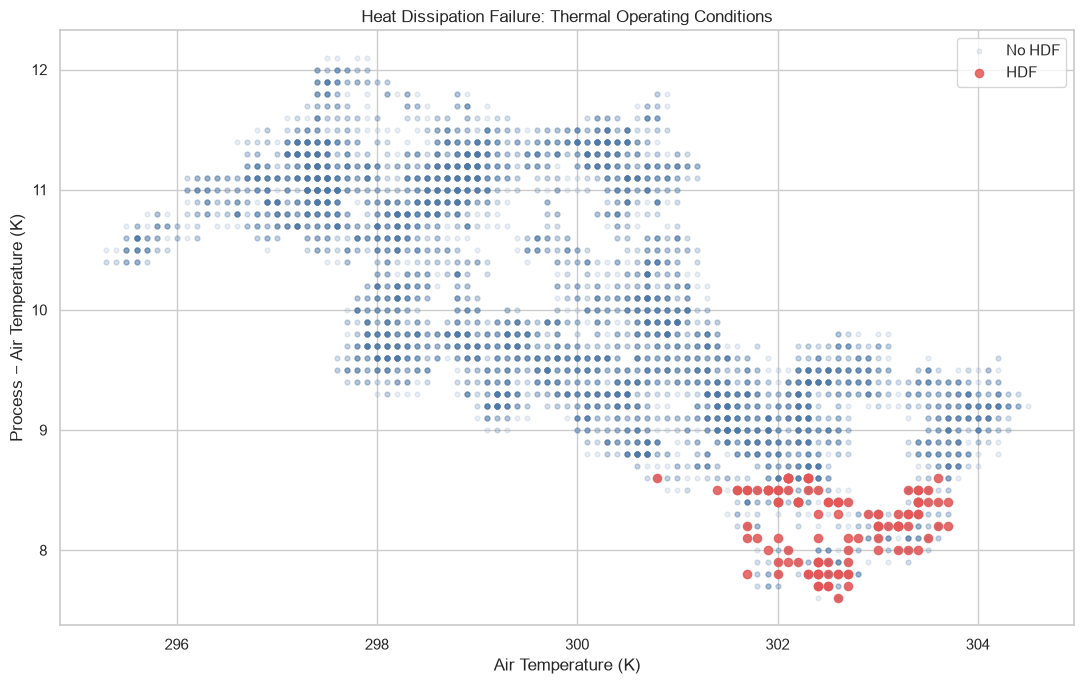

In [17]:
thermal_df = df.copy()

thermal_df["Temperature difference [K]"] = (
    thermal_df["Process temperature [K]"]
    - thermal_df["Air temperature [K]"]
)

print("=== THERMAL CONDITIONS BY HDF STATUS ===")

display(
    thermal_df.groupby("HDF")[
        [
            "Air temperature [K]",
            "Process temperature [K]",
            "Temperature difference [K]",
        ]
    ].agg(["mean", "median", "min", "max"]).round(3)
)

fig, ax = plt.subplots(figsize=(11, 7))

normal = thermal_df[thermal_df["HDF"] == 0]
hdf = thermal_df[thermal_df["HDF"] == 1]

ax.scatter(
    normal["Air temperature [K]"],
    normal["Temperature difference [K]"],
    alpha=0.12,
    s=12,
    color="#4C78A8",
    label="No HDF",
)

ax.scatter(
    hdf["Air temperature [K]"],
    hdf["Temperature difference [K]"],
    alpha=0.85,
    s=35,
    color="#E45756",
    label="HDF",
)

ax.set_title("Heat Dissipation Failure: Thermal Operating Conditions")
ax.set_xlabel("Air Temperature (K)")
ax.set_ylabel("Process − Air Temperature (K)")
ax.legend()

plt.tight_layout()
plt.show()